In [1]:
import os
import zipfile
import shutil
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import files
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
print("Available devices:")
for device in tf.config.list_physical_devices():
    print(device)

Available devices:
PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


In [3]:
uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded:
    print(filename)

Saving leaf.zip to leaf.zip
Saving non leaf.zip to non leaf.zip
Uploaded files:
leaf.zip
non leaf.zip


In [4]:
import os
import zipfile
import shutil

LEAF_ZIP = "/content/leaf.zip"
NOT_LEAF_ZIP = "/content/non leaf.zip"

DATA_DIR = "/content/leaf_dataset"
TEMP_DIR = "/content/temp_images"

assert os.path.exists(LEAF_ZIP), "leaf.zip not found. Upload it first."
assert os.path.exists(NOT_LEAF_ZIP), "non leaf.zip not found. Upload it first."

shutil.rmtree(DATA_DIR, ignore_errors=True)
shutil.rmtree(TEMP_DIR, ignore_errors=True)

os.makedirs(DATA_DIR + "/leaf")
os.makedirs(DATA_DIR + "/not_leaf")
os.makedirs(TEMP_DIR)

with zipfile.ZipFile(LEAF_ZIP, "r") as z:
    z.extractall(TEMP_DIR + "/leaf")

with zipfile.ZipFile(NOT_LEAF_ZIP, "r") as z:
    z.extractall(TEMP_DIR + "/not_leaf")

print("Both ZIP files extracted successfully!")
print("Both ZIP files extracted.")

Both ZIP files extracted successfully!
Both ZIP files extracted.


In [5]:
from PIL import Image

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def copy_images(source, destination):
    count = 0

    for root, dirs, filenames in os.walk(source):
        for filename in filenames:
            if filename.lower().endswith(IMAGE_EXTENSIONS):
                src = os.path.join(root, filename)
                dst = os.path.join(
                    destination, f"image_{count:05d}.jpg"
                )

                try:
                    with Image.open(src) as img:
                        img.convert("RGB").save(dst, "JPEG")
                    count += 1
                except Exception as e:
                    print("Skipped unreadable image:", filename)

    return count

leaf_count = copy_images(
    TEMP_DIR + "/leaf",
    DATA_DIR + "/leaf"
)

not_leaf_count = copy_images(
    TEMP_DIR + "/not_leaf",
    DATA_DIR + "/not_leaf"
)

print("Leaf images:", leaf_count)
print("Non-leaf images:", not_leaf_count)

assert leaf_count > 0, "No leaf images were found."
assert not_leaf_count > 0, "No non-leaf images were found."

Skipped unreadable image: 100000006.jpg


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Leaf images: 1019
Non-leaf images: 963


In [6]:
import random

random.seed(42)

SPLIT_DIR = "/content/split_dataset"
shutil.rmtree(SPLIT_DIR, ignore_errors=True)

for split in ["train", "val"]:
    for label in ["leaf", "not_leaf"]:
        os.makedirs(
            os.path.join(SPLIT_DIR, split, label),
            exist_ok=True
        )

for label in ["leaf", "not_leaf"]:
    source = os.path.join(DATA_DIR, label)
    images = [
        f for f in os.listdir(source)
        if f.lower().endswith(IMAGE_EXTENSIONS)
    ]

    random.shuffle(images)
    split_index = int(len(images) * 0.8)

    for filename in images[:split_index]:
        shutil.copy2(
            os.path.join(source, filename),
            os.path.join(SPLIT_DIR, "train", label, filename)
        )

    for filename in images[split_index:]:
        shutil.copy2(
            os.path.join(source, filename),
            os.path.join(SPLIT_DIR, "val", label, filename)
        )

print("Dataset split completed!")

Dataset split completed!


In [7]:
import tensorflow as tf

IMG_SIZE = (160, 160)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DIR + "/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DIR + "/val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

print("Class order:", train_ds.class_names)

Found 1585 files belonging to 2 classes.
Found 397 files belonging to 2 classes.
Class order: ['leaf', 'not_leaf']


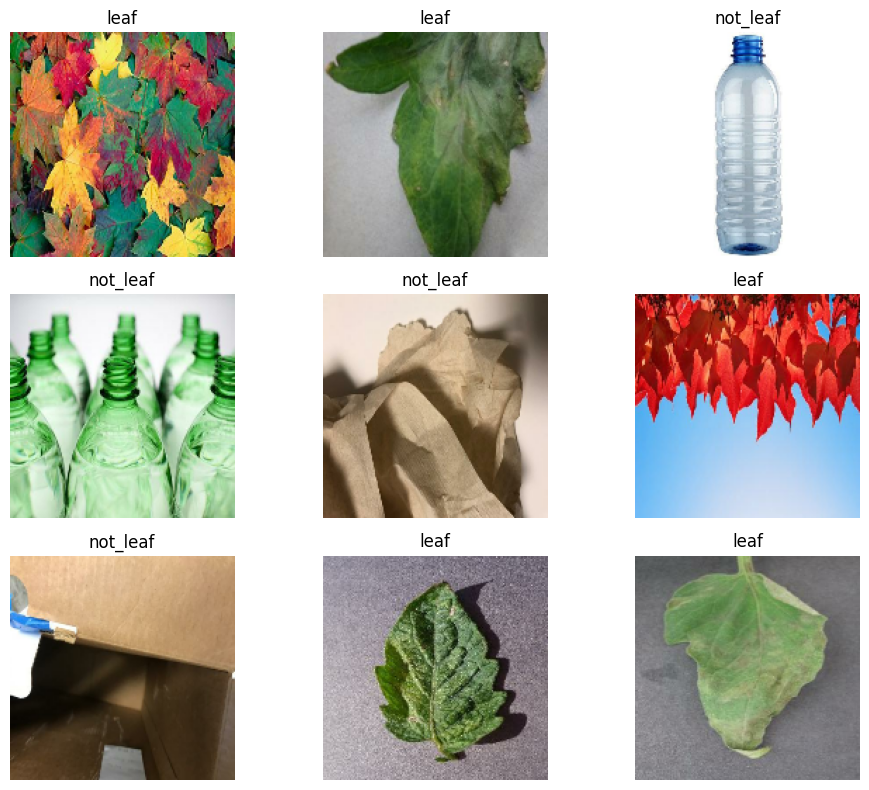

In [8]:
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))

        label = int(labels[i].numpy()[0])
        class_name = train_ds.class_names[label]

        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [85]:
from tensorflow.keras import layers, models

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    alpha=0.5,
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(shape=(160, 160, 3))

# MobileNetV2 expects input pixels scaled to [-1, 1]
x = layers.Rescaling(1.0 / 127.5, offset=-1)(inputs)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


3201480/3201480 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_9 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_0.50_160            │ (None, 5, 5, 1280)     │       706,224 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 707,505 (2.70 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 706,224 (2.69 MB)

In [86]:

import tensorflow as tf

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=[early_stop]
)

Epoch 1/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 24s 284ms/step - accuracy: 0.8833 - loss: 0.2882 - val_accuracy: 0.9849 - val_loss: 0.1147
Epoch 2/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 65ms/step - accuracy: 0.9792 - loss: 0.0883 - val_accuracy: 0.9849 - val_loss: 0.0763
Epoch 3/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - accuracy: 0.9823 - loss: 0.0635 - val_accuracy: 0.9874 - val_loss: 0.0602
Epoch 4/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 73ms/step - accuracy: 0.9855 - loss: 0.0515 - val_accuracy: 0.9874 - val_loss: 0.0523
Epoch 5/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 65ms/step - accuracy: 0.9893 - loss: 0.0426 - val_accuracy: 0.9899 - val_loss: 0.0483
Epoch 6/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - accuracy: 0.9893 - loss: 0.0390 - val_accuracy: 0.9874 - val_loss: 0.0444
Epoch 7/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - accuracy: 0.9918 - loss: 0.0328 - val_accuracy: 0.9899 - val_loss: 0.0422
Epoch 8/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - accuracy: 0.9943 - loss: 0.0249 - val_accuracy: 0.9874 -

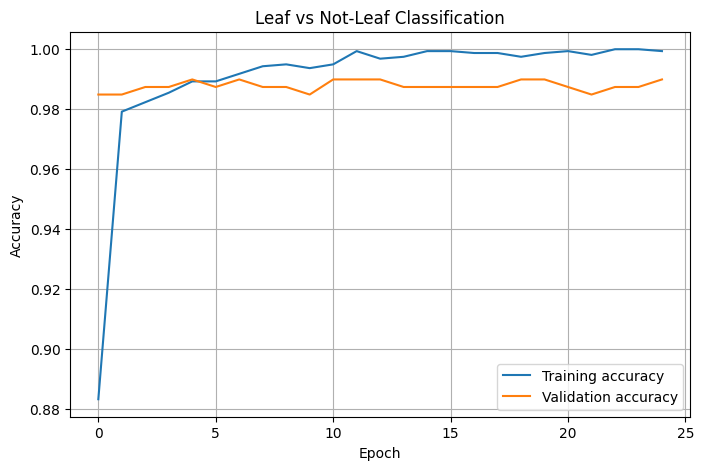

In [87]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Leaf vs Not-Leaf Classification")
plt.legend()
plt.grid(True)
plt.show()

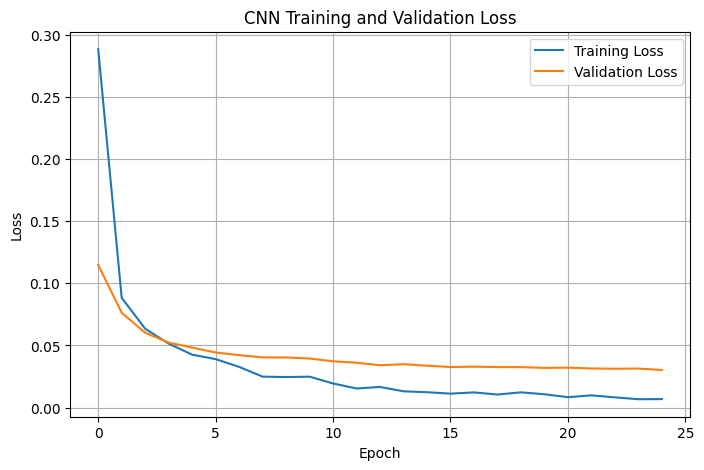

In [88]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


In [89]:
from sklearn.metrics import accuracy_score

y_true = []
y_pred = []

for images, labels in val_ds:
    probabilities = model.predict(images, verbose=0).ravel()

    y_true.extend(labels.numpy().ravel().astype(int))
    y_pred.extend((probabilities >= 0.5).astype(int))

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["LEAF", "NOT_LEAF"],
    zero_division=0
))
print("accuracy",accuracy_score(y_true, y_pred))
print("Confusion matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

              precision    recall  f1-score   support

        LEAF       1.00      0.99      0.99       204
    NOT_LEAF       0.98      0.99      0.99       193

    accuracy                           0.99       397
   macro avg       0.99      0.99      0.99       397
weighted avg       0.99      0.99      0.99       397

accuracy 0.9899244332493703
Confusion matrix:
[[201   3]
 [  1 192]]


Saving green-plastic-bags.jpg to green-plastic-bags.jpg
Image: green-plastic-bags.jpg
Prediction: NOT_LEAF
Not-leaf probability: 0.9887


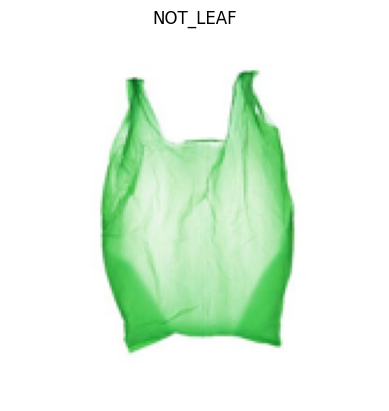

In [95]:
uploaded_test = files.upload()

from PIL import Image

for filename in uploaded_test:
    img = Image.open(filename).convert("RGB")
    img = img.resize(IMG_SIZE)

    image_array = np.array(img, dtype=np.float32)
    image_array = np.expand_dims(image_array, axis=0)

    probability_not_leaf = float(
        model.predict(image_array, verbose=0)[0][0]
    )

    if probability_not_leaf >= 0.5:
        prediction = "NOT_LEAF"
    else:
        prediction = "LEAF"

    print("Image:", filename)
    print("Prediction:", prediction)
    print("Not-leaf probability:", round(probability_not_leaf, 4))

    plt.imshow(img)
    plt.title(prediction)
    plt.axis("off")
    plt.show()

In [92]:
model.save("/content/leaf_classifier.keras")
print("Model saved.")

Model saved.


In [93]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# Reduce model size using dynamic-range quantization
converter.optimizations = [tf.lite.Optimize.DEFAULT]

tflite_model = converter.convert()

with open("/content/leaf_classifier.tflite", "wb") as f:
    f.write(tflite_model)

print("TFLite model size:",
      round(os.path.getsize("/content/leaf_classifier.tflite") / 1024, 2),
      "KB")

Saved artifact at '/tmp/tmp5_mppw75'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name='keras_tensor_329')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  133103653818768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133101004352272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133101004352080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133101004352464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133101004351312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133101004351696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133101004353232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133101004353040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133101004353424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133101004351504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1331010043

In [94]:
files.download("/content/leaf_classifier.keras")
files.download("/content/leaf_classifier.tflite")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [73]:
import tensorflow as tf
import os

model_path = "/content/leaf_classifier_int8.tflite"

interpreter = tf.lite.Interpreter(model_path=model_path)
interpreter.allocate_tensors()

print("Model size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")

print("\nInput tensors:")
for x in interpreter.get_input_details():
    print(x["name"], x["dtype"])

print("\nOutput tensors:")
for x in interpreter.get_output_details():
    print(x["name"], x["dtype"])

print("\nWeight tensor data types:")
details = interpreter.get_tensor_details()
types = {}
for x in details:
    types[str(x["dtype"])] = types.get(str(x["dtype"]), 0) + 1

print(types)

Model size: 5.17 MB

Input tensors:
serving_default_input_layer_7:0 <class 'numpy.int8'>

Output tensors:
StatefulPartitionedCall_1:0 <class 'numpy.int8'>

Weight tensor data types:
{"<class 'numpy.int8'>": 16, "<class 'numpy.int32'>": 11}


In [71]:
import tensorflow as tf
import numpy as np
import os

# Load your trained Keras model (using the correct .keras extension)
model = tf.keras.models.load_model("/content/leaf_classifier.keras")

# Representative dataset for calibration
# Using train_ds, which is the actual variable name in your notebook
def representative_dataset():
    for images, _ in train_ds.take(100):
        for image in images:
            yield [tf.cast(image[None, ...], tf.float32)]

# Convert and quantize to INT8
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset

converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_model = converter.convert()

# Save optimized model
output_path = "/content/leaf_classifier_int8.tflite"

with open(output_path, "wb") as f:
    f.write(tflite_model)

print("New model size:", round(os.path.getsize(output_path) / (1024 * 1024), 2), "MB")

Saved artifact at '/tmp/tmpkghhqgls'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name='input_layer_7')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  133103654651664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133103261452816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133103261018704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133103261016400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133103261009872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133103261014480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133103261011984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133103261017936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133103261019664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133103261013136: TensorSpec(shape=(), dtype=tf.resource, name=None)


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


New model size: 5.17 MB


In [72]:
import tensorflow as tf
import os

model_path = "/content/leaf_classifier_int8.tflite"

interpreter = tf.lite.Interpreter(model_path=model_path)
interpreter.allocate_tensors()

print("Model size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")

print("\nInput tensors:")
for x in interpreter.get_input_details():
    print(x["name"], x["dtype"])

print("\nOutput tensors:")
for x in interpreter.get_output_details():
    print(x["name"], x["dtype"])

print("\nWeight tensor data types:")
details = interpreter.get_tensor_details()
types = {}
for x in details:
    types[str(x["dtype"])] = types.get(str(x["dtype"]), 0) + 1

print(types)

Model size: 5.17 MB

Input tensors:
serving_default_input_layer_7:0 <class 'numpy.int8'>

Output tensors:
StatefulPartitionedCall_1:0 <class 'numpy.int8'>

Weight tensor data types:
{"<class 'numpy.int8'>": 16, "<class 'numpy.int32'>": 11}


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [74]:

import tensorflow as tf
import os

model_path = "/content/leaf_classifier_int8.tflite"

interpreter = tf.lite.Interpreter(model_path=model_path)
interpreter.allocate_tensors()

details = interpreter.get_tensor_details()

print("Large tensors:")
for t in details:
    shape = t["shape"]
    elements = 1
    for dim in shape:
        elements *= int(dim)

    size_mb = elements * t["dtype"]().nbytes / (1024 * 1024)

    if size_mb > 0.1:
        print(
            "Name:", t["name"],
            "| Shape:", shape,
            "| Type:", t["dtype"],
            "| Size:", round(size_mb, 2), "MB"
        )


Large tensors:
Name: sequential_7_1/dense_14_1/MatMul | Shape: [  128 41472] | Type: <class 'numpy.int8'> | Size: 5.06 MB
Name: sequential_7_1/conv2d_22_1/Relu;sequential_7_1/conv2d_22_1/BiasAdd;sequential_7_1/conv2d_22_1/convolution;sequential_7_1/conv2d_22_1/Squeeze2 | Shape: [  1 158 158  32] | Type: <class 'numpy.int8'> | Size: 0.76 MB
Name: sequential_7_1/max_pooling2d_21_1/MaxPool2d | Shape: [ 1 79 79 32] | Type: <class 'numpy.int8'> | Size: 0.19 MB
Name: sequential_7_1/conv2d_23_1/Relu;sequential_7_1/conv2d_23_1/BiasAdd;sequential_7_1/conv2d_23_1/convolution;sequential_7_1/conv2d_23_1/Squeeze1 | Shape: [ 1 77 77 64] | Type: <class 'numpy.int8'> | Size: 0.36 MB
Name: sequential_7_1/conv2d_24_1/Relu;sequential_7_1/conv2d_24_1/BiasAdd;sequential_7_1/conv2d_24_1/convolution;sequential_7_1/conv2d_24_1/Squeeze1 | Shape: [  1  36  36 128] | Type: <class 'numpy.int8'> | Size: 0.16 MB
